In [77]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json




In [78]:
data = pd.read_csv("données/LucasBenjamin_5c4f5967aac8be0001716a65.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,3679786.0,external-consent.html,external-html,3679837,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,3683774,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,66827.0,NaN,survey-dropdown,3750603,0.0-2.0,NaN,"{""0"":""25-40"",""1"":""M""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,19073.0,NaN,survey-text,3769676,0.0-3.0,NaN,"{""Q0"":""5c4f5967aac8be0001716a65""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9077.0,NaN,instructions,3778754,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":7422},{""page_i...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
329,NaN,NaN,lb-SeqAns-visual,6123528,0.0-224.0,NaN,NaN,NaN,3440.0,NaN,Stims/Gabor_img/Gabor_0.png,"200.5968591007,91.7505916269,92.3392353758","-45,45,45",NaN,51.719880,0.0,143.204726,0.0,NaN
330,NaN,NaN,lb-SeqAns-visual,6134666,0.0-225.0,NaN,NaN,NaN,2077.0,NaN,Stims/Gabor_img/Gabor_0.png,"105.3044423015,167.1775289424,193.8588713656,1...","45,0,0,45,45",NaN,-55.054336,0.0,161.849944,0.0,NaN
331,NaN,NaN,lb-SeqAns-visual,6138818,0.0-226.0,NaN,NaN,NaN,1126.0,NaN,Stims/Gabor_img/Gabor_0.png,10.8740975897,45,NaN,61.254903,0.0,55.874098,10.0,NaN


## Filtering du dataframe pour 1 sujet

In [79]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean)%180 # the best they could have done with what they were given

df_filtered = df_filtered.dropna(subset=["final_angle"])

In [80]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score,expected_angles,expected_targets
0,1111.0,[53.0656765392],[0.0],44.857118,53.065677,8,[53.0656765392],53.065677
1,866.0,[115.3385074976],[0.0],-60.203939,115.338507,10,[115.3385074976],115.338507
2,1386.0,"[182.445345918, 80.0600285054, 112.6830326927,...","[-45.0, 0.0, 0.0, 45.0, -45.0]",23.106327,120.803669,0,"[137.445345918, 80.0600285054, 112.6830326927,...",120.440252
3,933.0,"[63.4865787596, 64.5116961031, 54.468899969]","[0.0, 45.0, 45.0]",90.424405,91.057096,10,"[63.4865787596, 109.5116961031, 99.468899969]",90.822392
4,7436.0,"[134.4691792924, 74.3542585173, 100.6240442042]","[-45.0, 0.0, -45.0]",247.701729,73.167050,10,"[89.46917929240001, 74.3542585173, 55.62404420...",73.149161
...,...,...,...,...,...,...,...,...
195,3440.0,"[200.5968591007, 91.7505916269, 92.3392353758]","[-45.0, 45.0, 45.0]",51.719880,143.204726,0,"[155.5968591007, 136.75059162690002, 137.33923...",143.228895
196,2077.0,"[105.3044423015, 167.1775289424, 193.858871365...","[45.0, 0.0, 0.0, 45.0, 45.0]",-55.054336,161.849944,0,"[150.3044423015, 167.1775289424, 193.858871365...",162.125927
197,1126.0,[10.8740975897],[45.0],61.254903,55.874098,10,[55.8740975897],55.874098
198,3714.0,[91.4974168558],[0.0],-43.434931,91.497417,0,[91.4974168558],91.497417


In [81]:
# df_filtered["circular mean"] = CircularMean(df_filtered["expected_angles"])

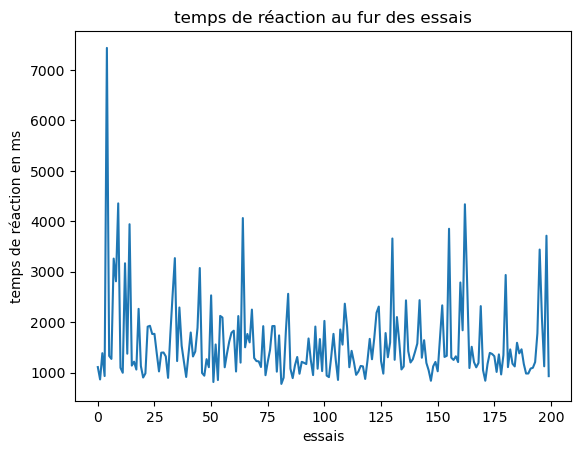

In [82]:
plt.plot(df_filtered["trial_rt"])
plt.title("temps de réaction au fur des essais")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
plt.show()

In [83]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if ~np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, a[i]))
    return(np.angle(resulting_vector))

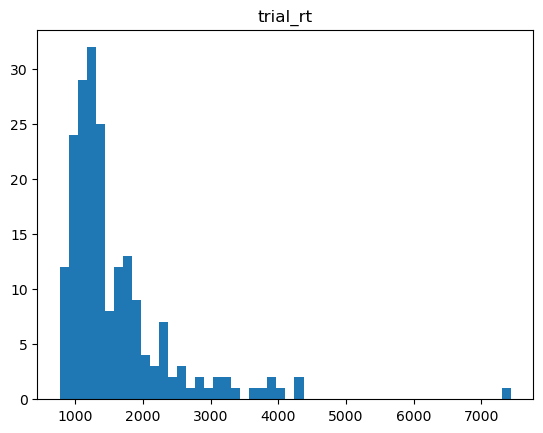

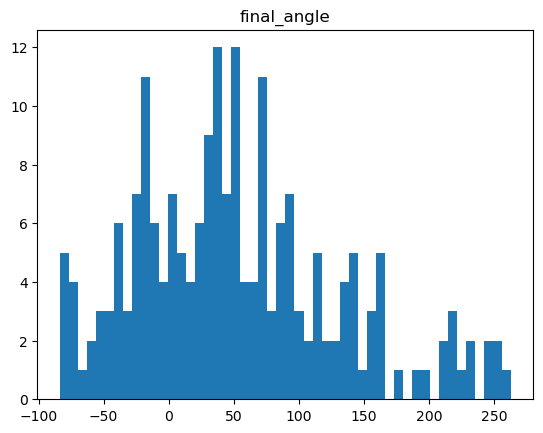

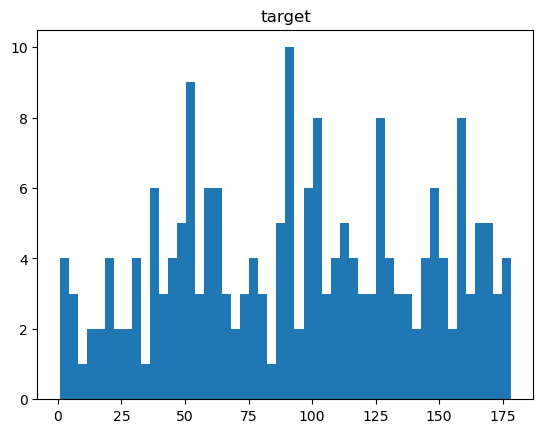

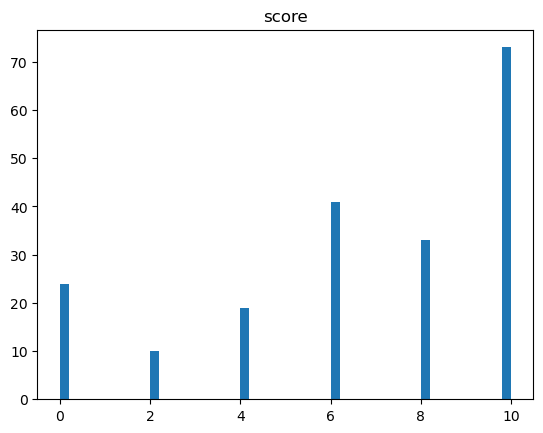

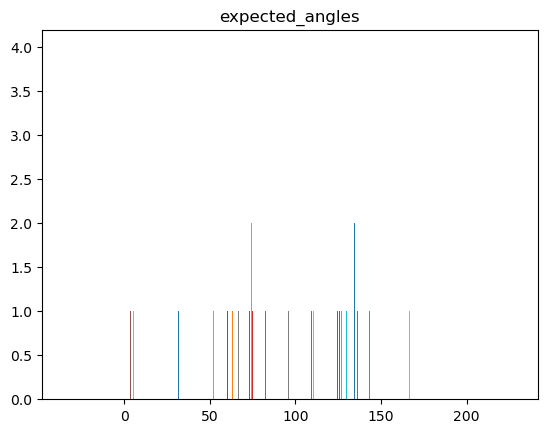

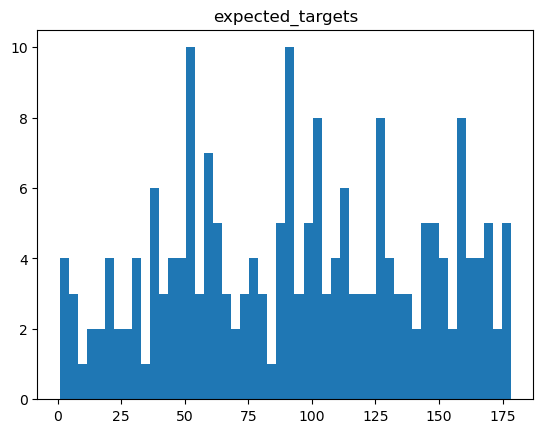

In [84]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

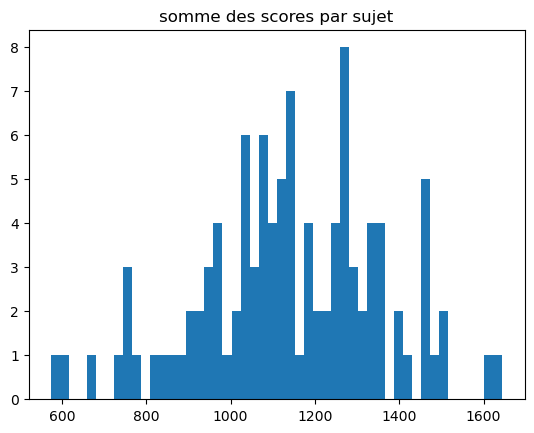

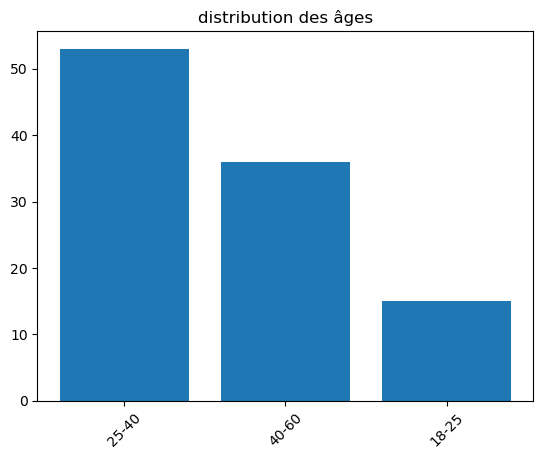

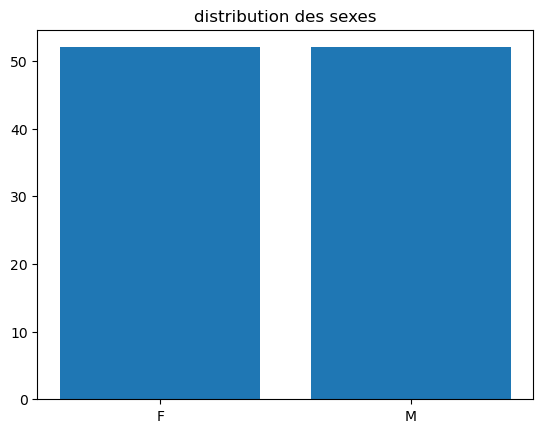

In [85]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sexe = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sexe = resp.get("1")        
        age_tot.append(age)
        sexe_tot.append(sexe)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sexe_tot

scores, ages, sexes = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title("somme des scores par sujet")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title("distribution des âges")
plt.show()

sex_counts = pd.Series(sexes).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("distribution des sexes")
plt.show()

In [88]:
print("il y a",sexes.count('F'), "femmes"), print("il y a",sexes.count('M'), 'hommes'), print("il y a",ages.count('18-25'), "personnes qui ont entre 18 et 25 ans"),
print("il y a",ages.count('25-40'), 'personnes qui ont entre 25 et 40 ans'), print("il y a",ages.count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


(None, None)

## Dispositoin des angles sur un cercle

ici je dois changer en mettant le cercle de -90° à 90°

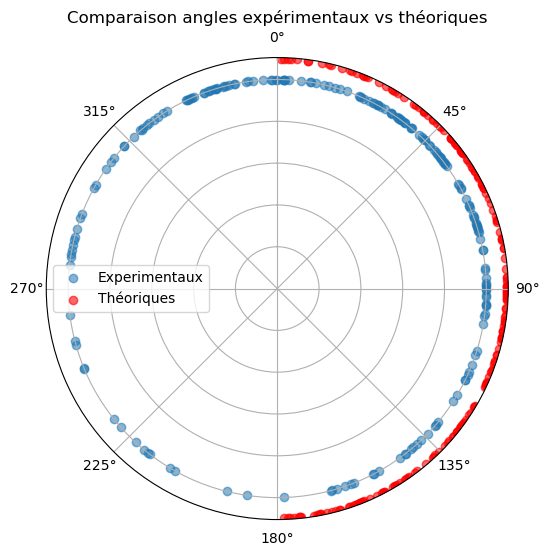

In [ ]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)
ax.set_theta_zero_location("N")   # 0° en haut
ax.set_theta_direction(-1)        # sens horaire


# angles en radians
theta_presented = np.deg2rad(df_filtered['final_angle'].values)
theta_targets = np.deg2rad(df_filtered['target'].values
)


# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()



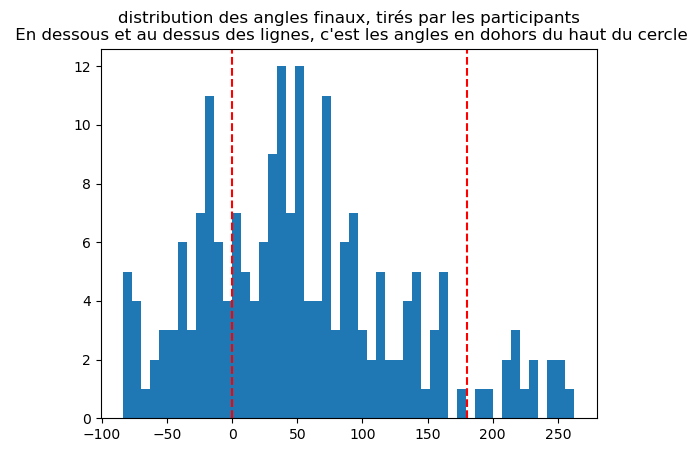

In [ ]:
plt.hist(df_filtered["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(180, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants\n En dessous et au dessus des lignes, c'est les angles en dohors du haut du cercle")
plt.show()

## implication des rotations dans la détermination des angles

fonction d'erreur circulaire 

In [ ]:
def distance_circular_error(a, b):
    return ((a - b + 90) % 180) - 90

In [ ]:
def angle_modulo_180(angle):
    return angle % 180

In [ ]:
for angle in df_filtered["expected_angles"][0]:
    old = angle
    new = angle_modulo_180(angle)
    print("old =", old, "new =", new)

old = 53.0656765392 new = 53.0656765392


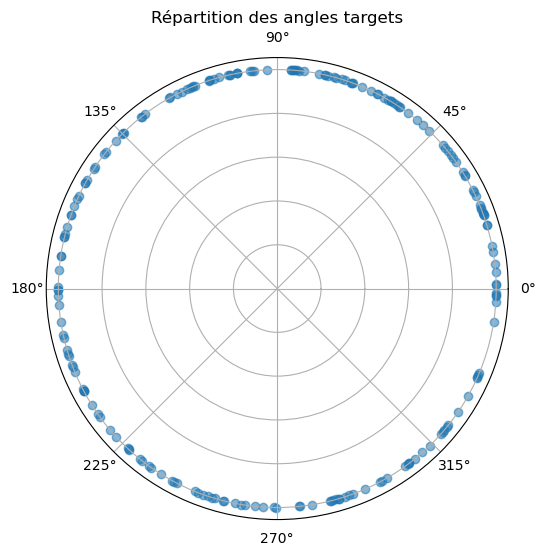

In [ ]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.scatter(df_filtered['expected_targets'], np.ones_like(df_filtered['expected_targets']),
           alpha=0.55)

ax.set_yticklabels([])
ax.set_title("Répartition des angles targets")
plt.show()

est ce que les participants ont bien répondu ? : performances 

In [ ]:
df_filtered["error_to_target"] = distance_circular_error(df_filtered["final_angle"], df_filtered["expected_targets"])

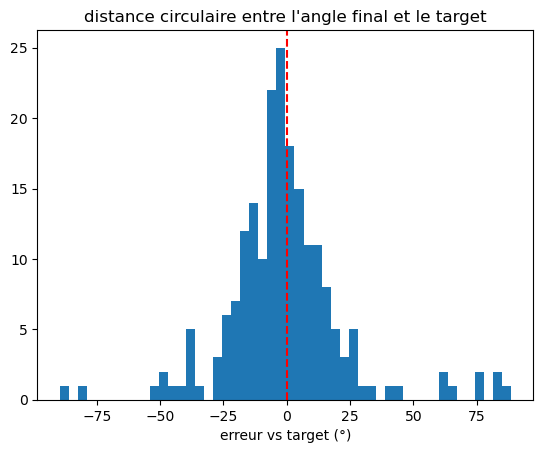

In [ ]:
plt.hist(df_filtered["error_to_target"], bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

est ce que ce participant se comporte en ignorant la rotation ?

In [ ]:
# 1. regarder la moyenne circulaire des angles vues par les participants sans les rotations
mean_presented_angles = df_filtered['presented_angles'].apply(np.mean)

In [ ]:
df_filtered['rotation_error'] = distance_circular_error(
    (df_filtered['final_angle']),
    mean_presented_angles
)

Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation

Gros pic autour de 0°
-> Les gens font bien la rotation

Pics autour de ±45°
-> Les gens répondent comme s’il n’y avait pas de rotation

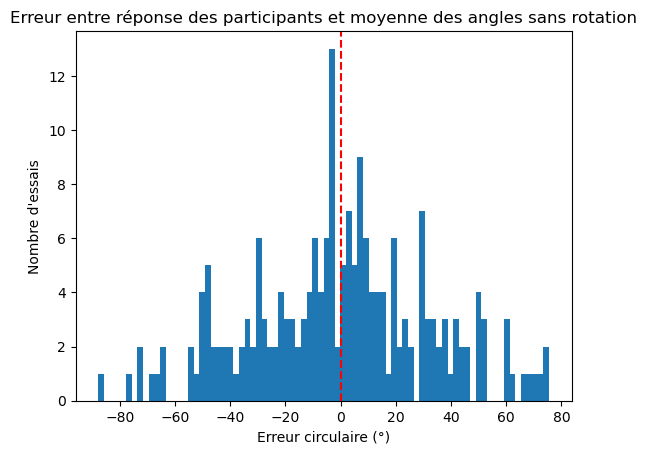

In [ ]:
plt.hist(df_filtered['rotation_error'], bins=80)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre réponse des participants et moyenne des angles sans rotation")
plt.show()
